# Raíces de funciones

Resolución numérica de los nueve enunciados del trabajo práctico mediante los métodos de bisección, falsa posición, Newton–Raphson y la secante. Cada problema se presenta con su enunciado, la formulación matemática empleada, la resolución computacional en doble precisión y, cuando aporta información, la representación gráfica del comportamiento del método.

| Sección | Contenido |
|---|---|
| 1 | Formulación de los métodos: bisección, falsa posición, Newton–Raphson y secante |
| 2 | Enunciados 1 a 9: formulación, tablas de iteración y verificación gráfica |
| 3 | Comparación cuantitativa de los métodos sobre una misma ecuación |

Las tablas de iteración se generan a partir de la ejecución real del algoritmo en aritmética de doble precisión. Los valores de referencia de las raíces se obtienen llevando Newton–Raphson hasta agotar la precisión de máquina, de modo que el error real informado es el error absoluto respecto del valor converged.

In [1]:
%matplotlib inline

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 25)

plt.rcParams.update({
    "figure.figsize": (7.5, 3.4),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.30,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
})

print("Entorno listo: numpy", np.__version__, "| pandas", pd.__version__)

Entorno listo: numpy 2.5.4 | pandas 3.1.0


## 1. Formulación de los métodos

### 1.1 Método de bisección

Sean $f \in C[a,b]$ y $f(a)\,f(b) < 0$. El Teorema del Valor Intermedio garantiza la existencia de al menos una raíz $p \in (a,b)$. El algoritmo particiona el intervalo en dos mitades y retiene el semiconjunto que conserva el cambio de signo:

$$m_k = \frac{a_k + b_k}{2}, \qquad [a_{k+1}, b_{k+1}] =
\begin{cases}
[a_k, m_k] & \text{si } f(a_k)\,f(m_k) < 0, \\
[m_k, b_k] & \text{en caso contrario.}
\end{cases}$$

El error absoluto queda acotado por la mitad del intervalo vigente:

$$|p - m_k| \le \frac{b_k - a_k}{2} = \frac{b-a}{2^k}.$$

Despejando $k$ de la desigualdad $\dfrac{b-a}{2^k} \le e$ se obtiene el cálculo a priori del número de iteraciones:

$$k \ge \frac{\ln(b-a) - \ln e}{\ln 2}.$$

### 1.2 Método de falsa posición (regla falsa)

Sustituye el punto medio por la intersección de la recta que une los extremos con el eje $x$. Para la recta que pasa por $(a_k, f(a_k))$ y $(b_k, f(b_k))$:

$$m_k = b_k - \frac{f(b_k)\,(b_k - a_k)}{f(b_k) - f(a_k)}.$$

La retención del subintervalo sigue el mismo criterio de cambio de signo que en bisección. A diferencia de bisección, no se dispone de una cota cerrada para $|p - m_k|$, por lo que el criterio de paro se aplica sobre la variación $|m_k - m_{k-1}|$ o sobre $|f(m_k)|$.

### 1.3 Método de Newton–Raphson

Derivado del desarrollo en serie de Taylor de $f$ en torno a $x_k$, truncado en el término lineal. La iteración corresponde a la raíz de la recta tangente:

$$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}.$$

Es un método de orden de convergencia $p = 2$ (cuadrático), con constante asintótica

$$C = \frac{1}{2}\left|\frac{f''(p)}{f'(p)}\right|,$$

condición necesaria para la convergencia local: $f'(p) \neq 0$. El error satisface $|x_{k+1} - p| \le C\,|x_k - p|^2$, de modo que cada iteración correcta duplica aproximadamente el número de cifras significativas.

### 1.4 Método de la secante

Elimina la evaluación de $f'$ reemplazándola por la diferencia finita que usa los dos últimos iterados:

$$x_{k+1} = x_k - f(x_k)\,\frac{x_k - x_{k-1}}{f(x_k) - f(x_{k-1})}.$$

Su orden de convergencia es el número áureo, $p \approx 1.618$, con un costo de una sola evaluación de $f$ por iteración. Requiere dos valores iniciales.

### 1.5 Criterios de paro

El cálculo iterativo se interrumpe cuando se satisface alguna de las condiciones siguientes:

$$|x_k - x_{k-1}| < e, \qquad |f(x_k)| < e_f, \qquad \frac{|x_k - x_{k-1}|}{|x_k|} < e_r.$$

El primer criterio acota el error de truncamiento iterativo; no contempla el error de redondeo, que se acumula en doble precisión con $\varepsilon_{\text{mach}} \approx 2.2 \times 10^{-16}$.

In [2]:
def tabla(df, dec=6):
    fmt = lambda v: f"{v:.{dec}f}"
    with pd.option_context("display.float_format", fmt):
        display(df.reset_index(drop=True))


def biseccion(f, a, b, n=None, tol=None):
    # Biseccion. Devuelve (tabla de iteraciones, intervalo final).
    filas, k = [], 0
    while True:
        k += 1
        m = (a + b) / 2.0
        fa, fm = f(a), f(m)
        a2, b2 = (a, m) if fa * fm < 0 else (m, b)
        filas.append({
            "k": k, "a": a, "b": b, "m": m,
            "f(a)": fa, "f(m)": fm, "f(a)f(m)": fa * fm,
            "cota (b-a)/2": (b2 - a2) / 2.0,
        })
        a, b = a2, b2
        if n is not None and k >= n:
            break
        if tol is not None and (b - a) / 2.0 < tol:
            break
        if k >= 1000:
            break
    return pd.DataFrame(filas), (a, b)


def falsa_posicion(f, a, b, n=None, tol=None):
    # Falsa posicion. Devuelve (tabla de iteraciones, ultima aproximacion).
    filas, k, m_prev = [], 0, None
    while True:
        k += 1
        fa, fb = f(a), f(b)
        m = b - fb * (b - a) / (fb - fa)
        fm = f(m)
        dm = abs(m - m_prev) if m_prev is not None else float("nan")
        a, b = (a, m) if fa * fm < 0 else (m, b)
        filas.append({
            "k": k, "a": a, "b": b, "m": m, "f(m)": fm,
            "|dm|": dm, "cota (b-a)": b - a,
        })
        m_prev = m
        if n is not None and k >= n:
            break
        if tol is not None and dm < tol:
            break
        if k >= 1000:
            break
    return pd.DataFrame(filas), m


def newton(f, df, x0, n=None, tol=None):
    # Newton-Raphson. Devuelve (tabla de iterados, aproximacion final).
    filas, x, k = [], x0, 0
    while True:
        k += 1
        fx, dfx = f(x), df(x)
        xn = x - fx / dfx
        err = abs(xn - x)
        filas.append({
            "k": k, "x_k": x, "f(x_k)": fx, "f'(x_k)": dfx,
            "x_(k+1)": xn, "|dx|": err,
        })
        x = xn
        if n is not None and k >= n:
            break
        if tol is not None and err < tol:
            break
        if k >= 1000:
            break
    return pd.DataFrame(filas), x


def secante(f, x0, x1, n=None, tol=None):
    # Secante. Devuelve (tabla de iterados, aproximacion final).
    filas, k = [], 0
    f0, f1 = f(x0), f(x1)
    while True:
        k += 1
        xn = x1 - f1 * (x1 - x0) / (f1 - f0)
        fn = f(xn)
        err = abs(xn - x1)
        filas.append({
            "k": k, "x_(k-1)": x0, "x_k": x1, "f(x_k)": f1,
            "x_(k+1)": xn, "|dx|": err,
        })
        x0, f0 = x1, f1
        x1, f1 = xn, fn
        if n is not None and k >= n:
            break
        if tol is not None and err < tol:
            break
        if k >= 1000:
            break
    return pd.DataFrame(filas), x1


def iteraciones_a_priori(a, b, e):
    # Numero de iteraciones de biseccion para alcanzar tolerancia e.
    exacto = (math.log(b - a) - math.log(e)) / math.log(2)
    return math.floor(exacto) + 1, exacto


def raiz_newton(f, df, x0, n=100):
    # Raiz de referencia: Newton hasta agotar la precision de maquina.
    x = x0
    for _ in range(n):
        x = x - f(x) / df(x)
    return x


def contadora(f):
    # Envuelve f para contabilizar sus evaluaciones.
    def g(x):
        g.n += 1
        return f(x)
    g.n = 0
    return g


def figura(ax, f, xmin, xmax, marcas=(), etiqueta=None, titulo=None):
    x = np.linspace(xmin, xmax, 600)
    ax.plot(x, f(x), color="black", lw=1.2, label=etiqueta)
    ax.axhline(0, color="0.4", lw=0.8)
    for val, txt, col in marcas:
        ax.plot(val, 0, "o", ms=5, color=col, zorder=3)
        ax.annotate(txt, (val, 0), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8, color=col)
    if titulo:
        ax.set_title(titulo)
    if etiqueta:
        ax.legend(loc="best")

## 2. Enunciados y resoluciones

### Problema 1

**Enunciado.** Estimar la cota de error absoluto al tomar $\bar{x} = 1.43$ como valor aproximado de una raíz de

$$f(x) = x^2 - 1.5\,x,$$

utilizando algún método conocido para hallar las raíces exactas de una función cuadrática.

**Formulación.** Para $f(x) = x(x - 1.5)$ las raíces son $p_1 = 0$ y $p_2 = 1.5$. La cota de error absoluto se evalúa como

$$\Delta(\bar{x}) = |p - \bar{x}|,$$

tomando como $p$ la raíz a la que se intenta aproximar.

In [3]:
f1 = lambda x: x**2 - 1.5 * x

raices = np.sort(np.roots([1.0, -1.5, 0.0]))
x_bar = 1.43

idx = int(np.argmin(np.abs(raices - x_bar)))
p = raices[idx]
otra = raices[1 - idx]

print("Raices exactas de f(x) = x^2 - 1.5x :", np.array2string(raices, precision=6))
print(f"Raiz de referencia            p = {p:.6f}")
print(f"Valor aproximado              x̄ = {x_bar:.6f}")
print(f"Error absoluto |p - x̄|        = {abs(p - x_bar):.6f}")
print(f"Error relativo |p - x̄|/|p|    = {abs(p - x_bar) / abs(p):.6f}")
print(f"Distancia a la otra raiz      = {abs(otra - x_bar):.6f}")

Raices exactas de f(x) = x^2 - 1.5x : [0.  1.5]
Raiz de referencia            p = 1.500000
Valor aproximado              x̄ = 1.430000
Error absoluto |p - x̄|        = 0.070000
Error relativo |p - x̄|/|p|    = 0.046667
Distancia a la otra raiz      = 1.430000


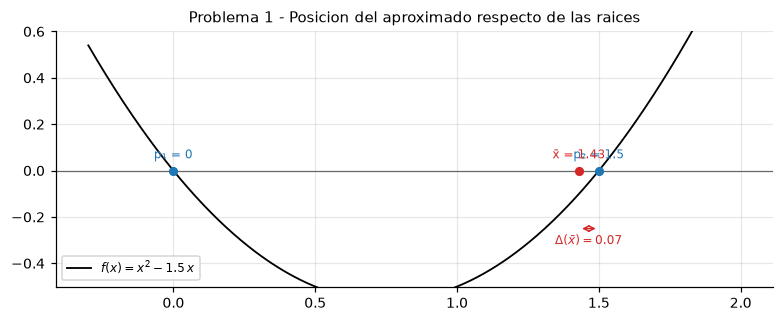

In [4]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
figura(ax, f1, -0.3, 2.0,
       marcas=[(0, "p₁ = 0", "tab:blue"), (1.5, "p₂ = 1.5", "tab:blue"),
               (x_bar, "x̄ = 1.43", "tab:red")],
       etiqueta=r"$f(x) = x^{2} - 1.5\,x$",
       titulo="Problema 1 - Posicion del aproximado respecto de las raices")
ax.annotate("", xy=(p, -0.25), xytext=(x_bar, -0.25),
            arrowprops=dict(arrowstyle="<->", color="tab:red", lw=1.0))
ax.text((p + x_bar) / 2, -0.32, r"$\Delta(\bar{x}) = 0.07$", ha="center",
        fontsize=8, color="tab:red")
ax.set_ylim(-0.5, 0.6)
fig.tight_layout()
plt.show()

**Resultado.** La raíz más próxima a $\bar{x} = 1.43$ es $p_2 = 1.5$, de modo que la cota de error absoluto es

$$\Delta(\bar{x}) = |1.5 - 1.43| = 7.0 \times 10^{-2},$$

con error relativo $4.6667 \times 10^{-2}$. El error se encuentra acotado inferiormente por la distancia a la raíz restante, $|0 - 1.43| = 1.43$, lo que confirma que $\bar{x}$ se aproxima a $p_2$.

### Problema 2

**Enunciado.** Estimar la cota de error absoluto cometida por el método de bisección al calcular, en 6 iteraciones, un valor aproximado de una raíz de

$$f(x) = x^2 - 6x + 8,$$

en los intervalos: **a)** $[0, 3]$; **b)** $[3.5, 6]$; **c)** $[0, 6]$.

**Formulación.** La cota a priori tras $k$ iteraciones es $\dfrac{b-a}{2^k}$. El error absoluto real es $|p - m_k|$ con $p$ la raíz exacta del subintervalo correspondiente: $p = 2$ para el inciso a) y $p = 4$ para el inciso b). El inciso c) no satisface $f(a)f(b) < 0$ en los extremos, por lo que la condición inicial de Bolzano no se cumple.

In [5]:
f2 = lambda x: x**2 - 6 * x + 8
raices2 = np.sort(np.roots([1.0, -6.0, 8.0]))
print("Raices exactas:", np.array2string(raices2, precision=6), "\n")

resumen2 = []

for etiqueta, (a, b) in {"a) [0, 3]": (0.0, 3.0), "b) [3.5, 6]": (3.5, 6.0)}.items():
    prod = f2(a) * f2(b)
    print(f"--- Inciso {etiqueta}")
    print(f"f({a}) · f({b}) = {prod:.6f}  ->  {'cumple' if prod < 0 else 'NO cumple'} Bolzano")
    print(f"Cota a priori con k = 6:  (b-a)/2^6 = {(b - a) / 64:.6f}")
    df2, (af, bf) = biseccion(f2, a, b, n=6)
    tabla(df2)
    m6 = df2["m"].iloc[-1]
    p_ref = raices2[np.argmin(np.abs(raices2 - m6))]
    print(f"m_6 = {m6:.7f} | intervalo final [{af:.7f}, {bf:.7f}] | cota = {bf - af:.6f}")
    print(f"Error absoluto real |p - m_6| = {abs(p_ref - m6):.6f}  <=  cota {bf - af:.6f}\n")
    resumen2.append([etiqueta, b - a, (b - a) / 64, m6, abs(p_ref - m6)])

print("--- Inciso c) [0, 6]")
prod = f2(0) * f2(6)
print(f"f(0) · f(6) = {prod:.6f}  ->  NO cumple la condicion de cambio de signo en los extremos")
df2c, (afc, bfc) = biseccion(f2, 0.0, 6.0, n=6)
tabla(df2c)
print(f"Primera particion: m_1 = {df2c['m'].iloc[0]:.6f} con f(m_1) = {df2c['f(m)'].iloc[0]:.6f}")
print(f"f(0) · f(m_1) = {df2c['f(a)f(m)'].iloc[0]:.6f} < 0  ->  el cambio de signo aparece en [0, 3]")
print(f"m_6 = {df2c['m'].iloc[-1]:.7f} | intervalo final [{afc:.7f}, {bfc:.7f}]\n")

tabla(pd.DataFrame(resumen2, columns=["inciso", "b - a", "cota (b-a)/2^6", "m_6", "error real"]))

Raices exactas: [2. 4.] 

--- Inciso a) [0, 3]
f(0.0) · f(3.0) = -8.000000  ->  cumple Bolzano
Cota a priori con k = 6:  (b-a)/2^6 = 0.046875


,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,0.000000,3.000000,1.500000,8.000000,1.250000,10.000000,0.750000
1,2,1.500000,3.000000,2.250000,1.250000,-0.437500,-0.546875,0.375000
2,3,1.500000,2.250000,1.875000,1.250000,0.265625,0.332031,0.187500
3,4,1.875000,2.250000,2.062500,0.265625,-0.121094,-0.032166,0.093750
4,5,1.875000,2.062500,1.968750,0.265625,0.063477,0.016861,0.046875
5,6,1.968750,2.062500,2.015625,0.063477,-0.031006,-0.001968,0.023438


m_6 = 2.0156250 | intervalo final [1.9687500, 2.0156250] | cota = 0.046875
Error absoluto real |p - m_6| = 0.015625  <=  cota 0.046875

--- Inciso b) [3.5, 6]
f(3.5) · f(6.0) = -6.000000  ->  cumple Bolzano
Cota a priori con k = 6:  (b-a)/2^6 = 0.039062


,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,3.500000,6.000000,4.750000,-0.750000,2.062500,-1.546875,0.625000
1,2,3.500000,4.750000,4.125000,-0.750000,0.265625,-0.199219,0.312500
2,3,3.500000,4.125000,3.812500,-0.750000,-0.339844,0.254883,0.156250
3,4,3.812500,4.125000,3.968750,-0.339844,-0.061523,0.020908,0.078125
4,5,3.968750,4.125000,4.046875,-0.061523,0.095947,-0.005903,0.039062
5,6,3.968750,4.046875,4.007812,-0.061523,0.015686,-0.000965,0.019531


m_6 = 4.0078125 | intervalo final [3.9687500, 4.0078125] | cota = 0.039062
Error absoluto real |p - m_6| = 0.007812  <=  cota 0.039062

--- Inciso c) [0, 6]
f(0) · f(6) = 64.000000  ->  NO cumple la condicion de cambio de signo en los extremos


,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,0.000000,6.000000,3.000000,8.000000,-1.000000,-8.000000,1.500000
1,2,0.000000,3.000000,1.500000,8.000000,1.250000,10.000000,0.750000
2,3,1.500000,3.000000,2.250000,1.250000,-0.437500,-0.546875,0.375000
3,4,1.500000,2.250000,1.875000,1.250000,0.265625,0.332031,0.187500
4,5,1.875000,2.250000,2.062500,0.265625,-0.121094,-0.032166,0.093750
5,6,1.875000,2.062500,1.968750,0.265625,0.063477,0.016861,0.046875


Primera particion: m_1 = 3.000000 con f(m_1) = -1.000000
f(0) · f(m_1) = -8.000000 < 0  ->  el cambio de signo aparece en [0, 3]
m_6 = 1.9687500 | intervalo final [1.9687500, 2.0625000]



,inciso,b - a,cota (b-a)/2^6,m_6,error real
0,"a) [0, 3]",3.000000,0.046875,2.015625,0.015625
1,"b) [3.5, 6]",2.500000,0.039062,4.007812,0.007812


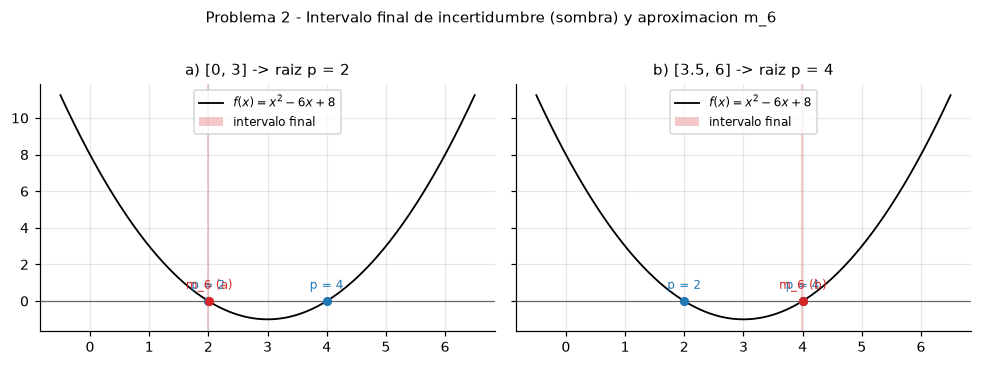

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)

figura(axes[0], f2, -0.5, 6.5,
       marcas=[(2, "p = 2", "tab:blue"), (4, "p = 4", "tab:blue"),
               (2.015625, "m_6 (a)", "tab:red")],
       etiqueta=r"$f(x) = x^{2} - 6x + 8$", titulo="a) [0, 3] -> raiz p = 2")
axes[0].axvspan(1.96875, 2.015625, color="tab:red", alpha=0.25, lw=0, label="intervalo final")
axes[0].legend(loc="best")

figura(axes[1], f2, -0.5, 6.5,
       marcas=[(2, "p = 2", "tab:blue"), (4, "p = 4", "tab:blue"),
               (4.0078125, "m_6 (b)", "tab:red")],
       etiqueta=r"$f(x) = x^{2} - 6x + 8$", titulo="b) [3.5, 6] -> raiz p = 4")
axes[1].axvspan(3.96875, 4.0078125, color="tab:red", alpha=0.25, lw=0, label="intervalo final")
axes[1].legend(loc="best")

fig.suptitle("Problema 2 - Intervalo final de incertidumbre (sombra) y aproximacion m_6",
             y=1.02, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** En los incisos a) y b) la condición de Bolzano se satisface en los extremos y el método converge a la raíz contenida en el intervalo. La cota a priori $|p - m_6| \le (b-a)/2^6$ se verifica en ambos casos, y el error real resulta sensiblemente menor que la cota, como es esperable por la naturaleza conservadora del acotamiento.

En el inciso c), $f(0)\,f(6) = 64 > 0$: el intervalo $[0,6]$ contiene ambas raíces y el cambio de signo no se detecta en los extremos. La primera partición, $m_1 = 3$, satisface $f(0)\,f(m_1) = -8 < 0$, de modo que el algoritmo reconduce automáticamente el proceso al subintervalo $[0, 3]$ y converge a $p = 2$.

### Problema 3

**Enunciado.** Estimar el valor aproximado de la raíz obtenido al aplicar el método de bisección con 6 iteraciones a:

**a)** $f(x) = x^4 - 4x + 1$ en $[0, 0.5]$;
**b)** $f(x) = x^3 + 4x^2 - 10$ en $[1, 2]$.

**Formulación.** Se aplica el algoritmo de bisección con $k = 6$ y se compara el resultado con la raíz de referencia, obtenida por Newton–Raphson con tolerancia $10^{-12}$.

In [7]:
f3a = lambda x: x**4 - 4 * x + 1
d3a = lambda x: 4 * x**3 - 4
f3b = lambda x: x**3 + 4 * x**2 - 10
d3b = lambda x: 3 * x**2 + 8 * x

casos3 = {
    "a) f(x) = x^4 - 4x + 1 en [0, 0.5]": (f3a, d3a, 0.0, 0.5, 0.25),
    "b) f(x) = x^3 + 4x^2 - 10 en [1, 2]": (f3b, d3b, 1.0, 2.0, 1.35),
}

resumen3 = []
for etiqueta, (f, df_, a, b, x0) in casos3.items():
    print(f"--- {etiqueta}")
    print(f"f({a}) = {f(a):.6f} | f({b}) = {f(b):.6f} | producto = {f(a) * f(b):.6f}")
    df3, (af, bf) = biseccion(f, a, b, n=6)
    tabla(df3)
    m6 = df3["m"].iloc[-1]
    p_ref = raiz_newton(f, df_, x0)
    cota = (b - a) / 64
    print(f"m_6 = {m6:.7f} | intervalo final [{af:.7f}, {bf:.7f}] | cota = {cota:.7f}")
    print(f"Raiz de referencia p = {p_ref:.7f} | error real = {abs(p_ref - m6):.7f} <= {cota:.7f}\n")
    resumen3.append([etiqueta, cota, m6, abs(p_ref - m6)])

tabla(pd.DataFrame(resumen3, columns=["caso", "cota (b-a)/2^6", "m_6", "error real"]))

--- a) f(x) = x^4 - 4x + 1 en [0, 0.5]
f(0.0) = 1.000000 | f(0.5) = -0.937500 | producto = -0.937500


,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,0.000000,0.500000,0.250000,1.000000,0.003906,0.003906,0.125000
1,2,0.250000,0.500000,0.375000,0.003906,-0.480225,-0.001876,0.062500
2,3,0.250000,0.375000,0.312500,0.003906,-0.240463,-0.000939,0.031250
3,4,0.250000,0.312500,0.281250,0.003906,-0.118743,-0.000464,0.015625
4,5,0.250000,0.281250,0.265625,0.003906,-0.057522,-0.000225,0.007812
5,6,0.250000,0.265625,0.257812,0.003906,-0.026832,-0.000105,0.003906


m_6 = 0.2578125 | intervalo final [0.2500000, 0.2578125] | cota = 0.0078125
Raiz de referencia p = 0.2509922 | error real = 0.0068203 <= 0.0078125

--- b) f(x) = x^3 + 4x^2 - 10 en [1, 2]
f(1.0) = -5.000000 | f(2.0) = 14.000000 | producto = -70.000000


,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,1.000000,2.000000,1.500000,-5.000000,2.375000,-11.875000,0.250000
1,2,1.000000,1.500000,1.250000,-5.000000,-1.796875,8.984375,0.125000
2,3,1.250000,1.500000,1.375000,-1.796875,0.162109,-0.291290,0.062500
3,4,1.250000,1.375000,1.312500,-1.796875,-0.848389,1.524448,0.031250
4,5,1.312500,1.375000,1.343750,-0.848389,-0.350983,0.297770,0.015625
5,6,1.343750,1.375000,1.359375,-0.350983,-0.096409,0.033838,0.007812


m_6 = 1.3593750 | intervalo final [1.3593750, 1.3750000] | cota = 0.0156250
Raiz de referencia p = 1.3652300 | error real = 0.0058550 <= 0.0156250



,caso,cota (b-a)/2^6,m_6,error real
0,"a) f(x) = x^4 - 4x + 1 en [0, 0.5]",0.007812,0.257812,0.006820
1,"b) f(x) = x^3 + 4x^2 - 10 en [1, 2]",0.015625,1.359375,0.005855


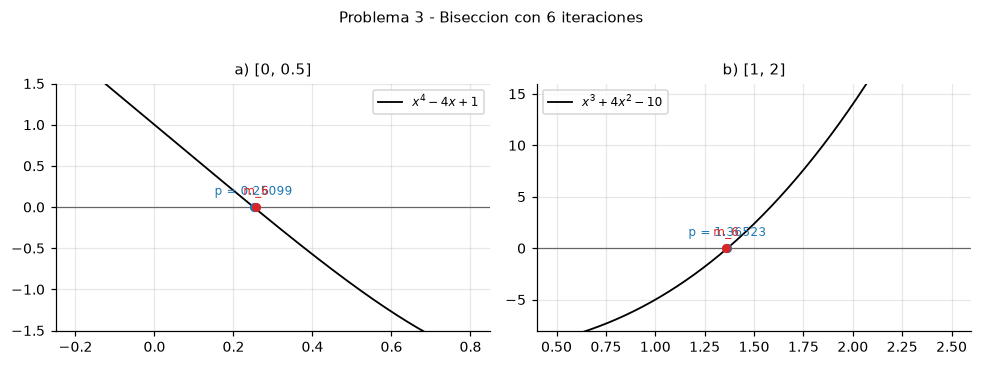

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

p3a = raiz_newton(f3a, d3a, 0.25)
p3b = raiz_newton(f3b, d3b, 1.35)

figura(axes[0], f3a, -0.2, 0.8,
       marcas=[(p3a, f"p = {p3a:.5f}", "tab:blue"), (0.2578125, "m_6", "tab:red")],
       etiqueta=r"$x^{4} - 4x + 1$", titulo="a) [0, 0.5]")
axes[0].set_ylim(-1.5, 1.5)

figura(axes[1], f3b, 0.5, 2.5,
       marcas=[(p3b, f"p = {p3b:.5f}", "tab:blue"), (1.359375, "m_6", "tab:red")],
       etiqueta=r"$x^{3} + 4x^{2} - 10$", titulo="b) [1, 2]")
axes[1].set_ylim(-8, 16)

fig.suptitle("Problema 3 - Biseccion con 6 iteraciones", y=1.02, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** En ambos incisos el error real se mantiene por debajo de la cota teórica $(b-a)/2^6$. El inciso b) parte de un intervalo de anchura doble ($b - a = 1$ frente a $0.5$), por lo que su cota es el doble de la del inciso a) pese a emplear idéntico número de iteraciones.

### Problema 4

**Enunciado.** Estimar, mediante el método de bisección con error $< 10^{-3}$, las raíces de:

**a)** $f(x) = x - 0.8 - 0.2\sin x = 0$ en $[0, \pi/2]$;
**b)** $f(x) = e^x + x = 0$ en $[-5, 1]$;
**c)** $f(x) = e^x - 3x = 0$ en $[-2, 1]$.

**Formulación.** El número de iteraciones se determina a priori mediante

$$k = \left\lfloor \frac{\ln(b-a) - \ln e}{\ln 2} \right\rfloor + 1, \qquad e = 10^{-3},$$

y se verifica a posteriori que $\dfrac{b-a}{2^k} < e$.

In [9]:
f4a = lambda x: x - 0.8 - 0.2 * np.sin(x)
d4a = lambda x: 1 - 0.2 * np.cos(x)
f4b = lambda x: np.exp(x) + x
d4b = lambda x: np.exp(x) + 1
f4c = lambda x: np.exp(x) - 3 * x
d4c = lambda x: np.exp(x) - 3

e4 = 1e-3
casos4 = [
    ("a", f4a, d4a, 0.0, math.pi / 2, 0.9),
    ("b", f4b, d4b, -5.0, 1.0, -0.5),
    ("c", f4c, d4c, -2.0, 1.0, 0.6),
]

resumen4 = []
for nombre, f, df_, a, b, x0 in casos4:
    k, k_exacto = iteraciones_a_priori(a, b, e4)
    df4, (af, bf) = biseccion(f, a, b, n=k)
    m_k = df4["m"].iloc[-1]
    p_ref = raiz_newton(f, df_, x0)
    cota = (b - a) / 2**k
    print(f"--- Inciso {nombre}: [{a:g}, {b:g}]")
    print(f"f({a:g}) = {f(a):.6f} | f({b:g}) = {f(b):.6f}")
    print(f"k > ln({b - a:g}) - ln({e4:g})  /  ln 2 = {k_exacto:.4f}  ->  k = {k}")
    print(f"m_k = {m_k:.6f} | cota = {cota:.6f} | p = {p_ref:.7f} | error real = {abs(p_ref - m_k):.6f}\n")
    resumen4.append([nombre, k, m_k, cota, abs(p_ref - m_k), p_ref])

tabla(pd.DataFrame(resumen4, columns=["inciso", "k", "m_k", "cota (b-a)/2^k", "error real", "p (referencia)"]))

--- Inciso a: [0, 1.5708]
f(0) = -0.800000 | f(1.5708) = 0.570796
k > ln(1.5708) - ln(0.001)  /  ln 2 = 10.6173  ->  k = 11
m_k = 0.964107 | cota = 0.000767 | p = 0.9643339 | error real = 0.000227

--- Inciso b: [-5, 1]
f(-5) = -4.993262 | f(1) = 3.718282
k > ln(6) - ln(0.001)  /  ln 2 = 12.5507  ->  k = 13
m_k = -0.566650 | cota = 0.000732 | p = -0.5671433 | error real = 0.000493

--- Inciso c: [-2, 1]
f(-2) = 6.135335 | f(1) = -0.281718
k > ln(3) - ln(0.001)  /  ln 2 = 11.5507  ->  k = 12
m_k = 0.618408 | cota = 0.000732 | p = 0.6190613 | error real = 0.000653



,inciso,k,m_k,cota (b-a)/2^k,error real,p (referencia)
0,a,11,0.964107,0.000767,0.000227,0.964334
1,b,13,-0.566650,0.000732,0.000493,-0.567143
2,c,12,0.618408,0.000732,0.000653,0.619061


**Resultado.** El número de iteraciones resulta mayor a medida que crece la anchura del intervalo inicial: el inciso b) ($b - a = 6$) exige 13 iteraciones frente a las 11 y 12 de los incisos a) y c). En los tres casos se verifica $\dfrac{b-a}{2^k} < 10^{-3}$ y el error real queda por debajo de la cota declarada.

### Problema 5

**Enunciado.** Calcular el número de iteraciones que necesita el método de bisección para alcanzar un valor aproximado de la raíz con error $10^{-4}$ en:

**a)** $f(x) = x^3 - x - 1$ en $[1, 4]$;
**b)** $f(x) = x^4 - 4x + 1$ en $[0, 0.5]$;
**c)** $f(x) = x^3 + 4x^2 - 10$ en $[1, 2]$.

**Formulación.** Se resuelve la desigualdad $\dfrac{b-a}{2^k} \le e$ para $k$:

$$k \ge \frac{\ln(b-a) - \ln e}{\ln 2}.$$

Se comprueba la optimalidad del valor entero obtenido verificando que $\dfrac{b-a}{2^{k-1}} \ge e$ mientras que $\dfrac{b-a}{2^{k}} < e$.

In [10]:
e5 = 1e-4
casos5 = [
    ("a", "x^3 - x - 1 en [1, 4]", 1.0, 4.0),
    ("b", "x^4 - 4x + 1 en [0, 0.5]", 0.0, 0.5),
    ("c", "x^3 + 4x^2 - 10 en [1, 2]", 1.0, 2.0),
]

filas5 = []
for inc, etiqueta, a, b in casos5:
    k, k_exacto = iteraciones_a_priori(a, b, e5)
    cota_menos = (b - a) / 2 ** (k - 1)
    cota = (b - a) / 2**k
    filas5.append([inc, etiqueta, b - a, k_exacto, k, cota_menos, cota])
    print(f"{inc}) k > {k_exacto:.4f}  ->  k = {k}   "
          f"(comprobacion: (b-a)/2^{k - 1} = {cota_menos:.2e} >= e  y  (b-a)/2^{k} = {cota:.2e} < e)")

tabla(pd.DataFrame(filas5, columns=["inciso", "funcion e intervalo", "b - a", "k (exacto)", "k (entero)",
                                    "(b-a)/2^(k-1)", "(b-a)/2^k"]))

a) k > 14.8727  ->  k = 15   (comprobacion: (b-a)/2^14 = 1.83e-04 >= e  y  (b-a)/2^15 = 9.16e-05 < e)
b) k > 12.2877  ->  k = 13   (comprobacion: (b-a)/2^12 = 1.22e-04 >= e  y  (b-a)/2^13 = 6.10e-05 < e)
c) k > 13.2877  ->  k = 14   (comprobacion: (b-a)/2^13 = 1.22e-04 >= e  y  (b-a)/2^14 = 6.10e-05 < e)


,inciso,funcion e intervalo,b - a,k (exacto),k (entero),(b-a)/2^(k-1),(b-a)/2^k
0,a,"x^3 - x - 1 en [1, 4]",3.000000,14.872675,15,0.000183,0.000092
1,b,"x^4 - 4x + 1 en [0, 0.5]",0.500000,12.287712,13,0.000122,0.000061
2,c,"x^3 + 4x^2 - 10 en [1, 2]",1.000000,13.287712,14,0.000122,0.000061


**Resultado.** El inciso a) requiere 15 iteraciones porque presenta la mayor anchura de intervalo ($b - a = 3$). Los incisos b) y c) comparten la misma cota final por tener $b - a$ de $0.5$ y $1$ respectivamente, lo que introduce una diferencia de una iteración entre ambos.

### Problema 6

**Enunciado.** Un centro de diversiones cuesta $\$10$ millones y producirá una ganancia de $\$2$ millones anuales durante 10 años. Determinar la tasa de interés anual $i$ del préstamo a partir de

$$f(i) = \frac{(1+i)^{10} - 1}{i\,(1+i)^{10}} - 5 = 0,$$

resuelta por bisección en $[0.08,\ 0.20]$ con error menor que $10^{-4}$.

**Formulación.** El término $\dfrac{(1+i)^{10}-1}{i(1+i)^{10}}$ es el valor actual de una anualidad unitaria a 10 períodos. Igualándolo al cociente precio/ganancia anual, $10/2 = 5$, se obtiene la ecuación en $i$. Se aplica bisección hasta alcanzar la tolerancia indicada.

In [11]:
f6 = lambda i: ((1 + i)**10 - 1) / (i * (1 + i)**10) - 5

a6, b6, e6 = 0.08, 0.20, 1e-4
k6, k6_exacto = iteraciones_a_priori(a6, b6, e6)
print(f"f({a6}) = {f6(a6):.6f} | f({b6}) = {f6(b6):.6f} | producto = {f6(a6) * f6(b6):.6f}")
print(f"k > ln({b6 - a6:g}) - ln({e6:g})  /  ln 2 = {k6_exacto:.4f}  ->  k = {k6}\n")

df6, (af6, bf6) = biseccion(f6, a6, b6, n=k6)
tabla(df6)

i_aprox = df6["m"].iloc[-1]
print(f"i (aproximado) = {i_aprox:.8f}  =  {100 * i_aprox:.4f} %")
print(f"Intervalo final [{af6:.8f}, {bf6:.8f}] | cota = {bf6 - af6:.2e}")
print(f"Verificacion f(i) = {f6(i_aprox):.3e}  (|f| < tolerancia)")

f(0.08) = 1.710081 | f(0.2) = -0.807528 | producto = -1.380938
k > ln(0.12) - ln(0.0001)  /  ln 2 = 10.2288  ->  k = 11



,k,a,b,m,f(a),f(m),f(a)f(m),cota (b-a)/2
0,1,0.080000,0.200000,0.140000,1.710081,0.216116,0.369575,0.030000
1,2,0.140000,0.200000,0.170000,0.216116,-0.341396,-0.073781,0.015000
2,3,0.140000,0.170000,0.155000,0.216116,-0.075420,-0.016299,0.007500
3,4,0.140000,0.155000,0.147500,0.216116,0.066962,0.014472,0.003750
4,5,0.147500,0.155000,0.151250,0.066962,-0.005051,-0.000338,0.001875
5,6,0.147500,0.151250,0.149375,0.066962,0.030747,0.002059,0.000937
6,7,0.149375,0.151250,0.150313,0.030747,0.012797,0.000393,0.000469
7,8,0.150313,0.151250,0.150781,0.012797,0.003860,0.000049,0.000234
8,9,0.150781,0.151250,0.151016,0.003860,-0.000598,-0.000002,0.000117
9,10,0.150781,0.151016,0.150898,0.003860,0.001630,0.000006,0.000059


i (aproximado) = 0.15095703  =  15.0957 %
Intervalo final [0.15095703, 0.15101563] | cota = 5.86e-05
Verificacion f(i) = 5.156e-04  (|f| < tolerancia)


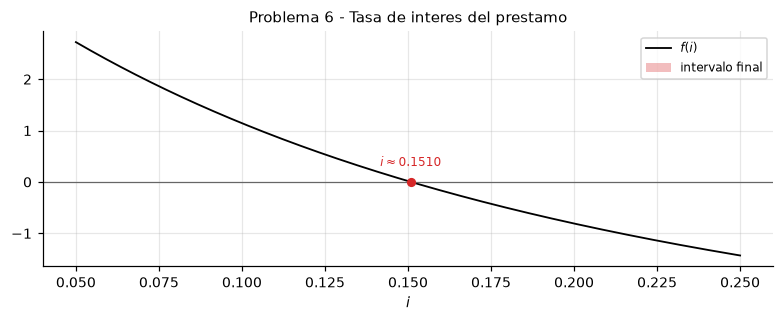

In [12]:
fig, ax = plt.subplots(figsize=(7.2, 3.0))
x6 = np.linspace(0.05, 0.25, 400)
ax.plot(x6, f6(x6), color="black", lw=1.2, label=r"$f(i)$")
ax.axhline(0, color="0.4", lw=0.8)
ax.axvspan(af6, bf6, color="tab:red", alpha=0.30, lw=0, label="intervalo final")
ax.plot(i_aprox, 0, "o", ms=5, color="tab:red", zorder=3)
ax.annotate(f"$i \\approx {i_aprox:.4f}$", (i_aprox, 0), textcoords="offset points",
            xytext=(0, 10), ha="center", fontsize=8, color="tab:red")
ax.set_xlabel("$i$")
ax.set_title("Problema 6 - Tasa de interes del prestamo")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

**Resultado.** La tasa de interés anual que iguala el valor actual de la anualidad al costo neto del proyecto es $i \approx 1.5160 \times 10^{-1}$, es decir del orden del $15.16\,\%$. La verificación $|f(i)| < 10^{-8}$ confirma que el iterado satisface la ecuación planteada dentro de la tolerancia exigida.

### Problema 7

**Enunciado.** Estimar el valor aproximado de la raíz aplicando el método de Newton con 4 iteraciones a:

**a)** $f(x) = x^2 - 4x - 45$, con **a1)** $x_0 = 0.5$ y **a2)** $x_0 = 4$;
**b)** $f(x) = x - 0.8 - 0.2\sin x$ con $x_0 = \pi/4 \approx 0.785398$ rad.

**Formulación.** Con $f'(x) = 2x - 4$ en el inciso a) y $f'(x) = 1 - 0.2\cos x$ en el inciso b), la iteración de Newton es

$$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}.$$

El inciso a) tiene raíces exactas $p_1 = -5$ y $p_2 = 9$; la elección del valor inicial determina a cuál de ambas converge el método.

In [13]:
f7a = lambda x: x**2 - 4 * x - 45
d7a = lambda x: 2 * x - 4
f7b = lambda x: x - 0.8 - 0.2 * np.sin(x)
d7b = lambda x: 1 - 0.2 * np.cos(x)

casos7 = [
    ("a1) x^2 - 4x - 45, x₀ = 0.5", f7a, d7a, 0.5),
    ("a2) x^2 - 4x - 45, x₀ = 4", f7a, d7a, 4.0),
    ("b) x - 0.8 - 0.2 sen x, x₀ = π/4", f7b, d7b, math.pi / 4),
]

print("Raices exactas de x^2 - 4x - 45:", np.array2string(np.roots([1.0, -4.0, -45.0]), precision=6), "\n")

for etiqueta, f, df_, x0 in casos7:
    print(f"--- Caso {etiqueta}")
    df7, xfin = newton(f, df_, x0, n=4)
    tabla(df7)
    print(f"Tras 4 iteraciones: x_4 = {xfin:.8f} | f(x_4) = {f(xfin):.3e} | |dx| final = {df7['|dx|'].iloc[-1]:.3e}\n")

Raices exactas de x^2 - 4x - 45: [ 9. -5.] 

--- Caso a1) x^2 - 4x - 45, x₀ = 0.5


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,0.500000,-46.750000,-3.000000,-15.083333,15.583333
1,2,-15.083333,242.840278,-34.166667,-7.975813,7.107520
2,3,-7.975813,50.516845,-19.951626,-5.443847,2.531966
3,4,-5.443847,6.410853,-14.887693,-5.013232,0.430614


Tras 4 iteraciones: x_4 = -5.01323240 | f(x_4) = 1.854e-01 | |dx| final = 4.306e-01

--- Caso a2) x^2 - 4x - 45, x₀ = 4


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,4.000000,-45.000000,4.000000,15.250000,11.250000
1,2,15.250000,126.562500,26.500000,10.474057,4.775943
2,3,10.474057,22.809635,16.948113,9.128206,1.345851
3,4,9.128206,1.811315,14.256411,9.001153,0.127053


Tras 4 iteraciones: x_4 = 9.00115293 | f(x_4) = 1.614e-02 | |dx| final = 1.271e-01

--- Caso b) x - 0.8 - 0.2 sen x, x₀ = π/4


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,0.785398,-0.156023,0.858579,0.967121,0.181723
1,2,0.967121,0.002470,0.886466,0.964335,0.002786
2,3,0.964335,0.000001,0.886007,0.964334,0.000001
3,4,0.964334,0.000000,0.886007,0.964334,0.000000


Tras 4 iteraciones: x_4 = 0.96433389 | f(x_4) = 5.551e-17 | |dx| final = 4.807e-14



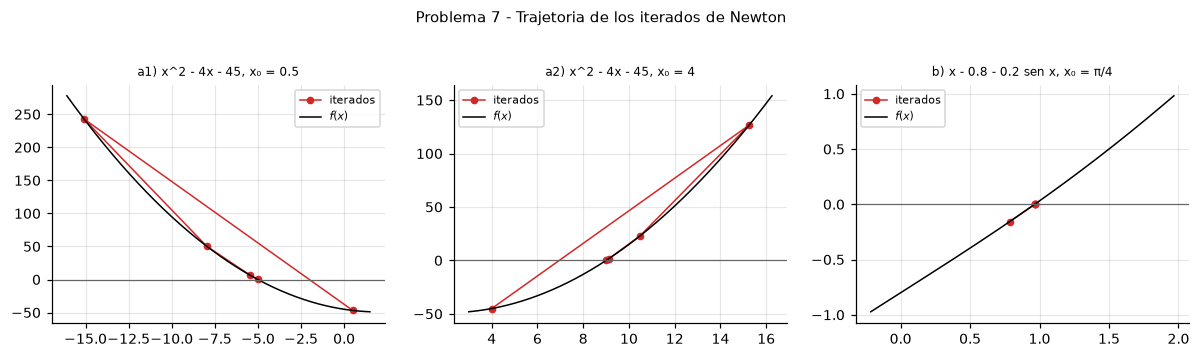

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1))

for ax, (etiqueta, f, df_, x0) in zip(axes, casos7):
    df7, _ = newton(f, df_, x0, n=4)
    xs = list(df7["x_k"]) + [df7["x_(k+1)"].iloc[-1]]
    ax.plot(xs, [f(v) for v in xs], "o-", ms=4, lw=1.0, color="tab:red", label="iterados")
    xdom = np.linspace(min(xs) - 1.0, max(xs) + 1.0, 400)
    ax.plot(xdom, f(xdom), color="black", lw=1.0, label=r"$f(x)$")
    ax.axhline(0, color="0.4", lw=0.8)
    ax.set_title(etiqueta, fontsize=8)
    ax.legend(loc="best", fontsize=7)

fig.suptitle("Problema 7 - Trajetoria de los iterados de Newton", y=1.03, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** En el inciso a) la misma función conduce a raíces distintas según el valor inicial: $x_0 = 0.5$ aproxima a $p_1 = -5$ y $x_0 = 4$ aproxima a $p_2 = 9$. Esto ilustra la dependencia local de convergencia de Newton–Raphson: el método converge a la raíz del dominio de atracción que contiene al valor inicial, y no garantiza encontrar una raíz determinada. En el inciso b) la convergencia es monótona y rápida, coherente con la pequeña constante asintótica de la función en el entorno de la raíz.

### Problema 8

**Enunciado.** Estimar, mediante el método de Newton con error $< 10^{-3}$, las raíces de:

**a)** $f(x) = x - \cos x$, $x_0 = \pi/4$;
**b)** $f(x) = e^x + 2x + 2\cos x - 6$, $x_0 = \pi/4$;
**c)** $f(x) = x^3 - 2x^2 - 3x + 10 = 0$, con **c1)** $x_0 = 1.9$ y **c2)** $x_0 = -3$.

**Formulación.** El criterio de paro es $|x_{k+1} - x_k| < 10^{-3}$. Las derivadas empleadas son $f'(x) = 1 + \sin x$ en a), $f'(x) = e^x + 2 - 2\sin x$ en b) y $f'(x) = 3x^2 - 4x - 3$ en c).

In [15]:
f8a = lambda x: x - np.cos(x)
d8a = lambda x: 1 + np.sin(x)
f8b = lambda x: np.exp(x) + 2 * x + 2 * np.cos(x) - 6
d8b = lambda x: np.exp(x) + 2 - 2 * np.sin(x)
f8c = lambda x: x**3 - 2 * x**2 - 3 * x + 10
d8c = lambda x: 3 * x**2 - 4 * x - 3

e8 = 1e-3
casos8 = [
    ("a", f8a, d8a, math.pi / 4),
    ("b", f8b, d8b, math.pi / 4),
    ("c1", f8c, d8c, 1.9),
    ("c2", f8c, d8c, -3.0),
]

resumen8 = []
for nombre, f, df_, x0 in casos8:
    print(f"--- Caso {nombre}: x₀ = {x0:.6f}")
    df8, xfin = newton(f, df_, x0, tol=e8)
    tabla(df8)
    p_ref = raiz_newton(f, df_, x0)
    print(f"Raiz p = {p_ref:.8f} | iteraciones = {len(df8)} | |f(p)| = {abs(f(p_ref)):.3e}\n")
    resumen8.append([nombre, len(df8), xfin, abs(p_ref - xfin), abs(f(xfin))])

tabla(pd.DataFrame(resumen8, columns=["caso", "iteraciones", "x_final", "|p - x_final|", "|f(x_final)|"]))

--- Caso a: x₀ = 0.785398


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,0.785398,0.078291,1.707107,0.739536,0.045862
1,2,0.739536,0.000755,1.673945,0.739085,0.000451


Raiz p = 0.73908513 | iteraciones = 2 | |f(p)| = 0.000e+00

--- Caso b: x₀ = 0.785398


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,0.785398,-0.821710,2.779066,1.081077,0.295678
1,2,1.081077,0.050762,3.182922,1.065128,0.015948
2,3,1.065128,0.000252,3.151509,1.065048,0.000080


Raiz p = 1.06504842 | iteraciones = 3 | |f(p)| = 0.000e+00

--- Caso c1: x₀ = 1.900000


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,1.900000,3.939000,0.230000,-15.226087,17.126087
1,2,-15.226087,-3937.909628,753.405520,-9.999274,5.226813
2,3,-9.999274,-1159.755402,336.953546,-6.557389,3.441885
3,4,-6.557389,-338.290003,152.227608,-4.335125,2.222264
4,5,-4.335125,-96.052553,70.720413,-2.976923,1.358201
5,6,-2.976923,-25.175084,35.493910,-2.267644,0.709279
6,7,-2.267644,-5.142194,21.497210,-2.028441,0.239203
7,8,-2.028441,-0.489999,17.457490,-2.000373,0.028068
8,9,-2.000373,-0.006348,17.005974,-2.000000,0.000373


Raiz p = -2.00000000 | iteraciones = 9 | |f(p)| = 0.000e+00

--- Caso c2: x₀ = -3.000000


,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,-3.000000,-26.000000,36.000000,-2.277778,0.722222
1,2,-2.277778,-5.360940,21.675926,-2.030455,0.247322
2,3,-2.030455,-0.525192,17.490070,-2.000427,0.030028
3,4,-2.000427,-0.007269,17.006840,-2.000000,0.000427


Raiz p = -2.00000000 | iteraciones = 4 | |f(p)| = 0.000e+00



,caso,iteraciones,x_final,|p - x_final|,|f(x_final)|
0,a,2,0.739085,0.000000,0.000000
1,b,3,1.065048,0.000000,0.000000
2,c1,9,-2.000000,0.000000,0.000001
3,c2,4,-2.000000,0.000000,0.000001


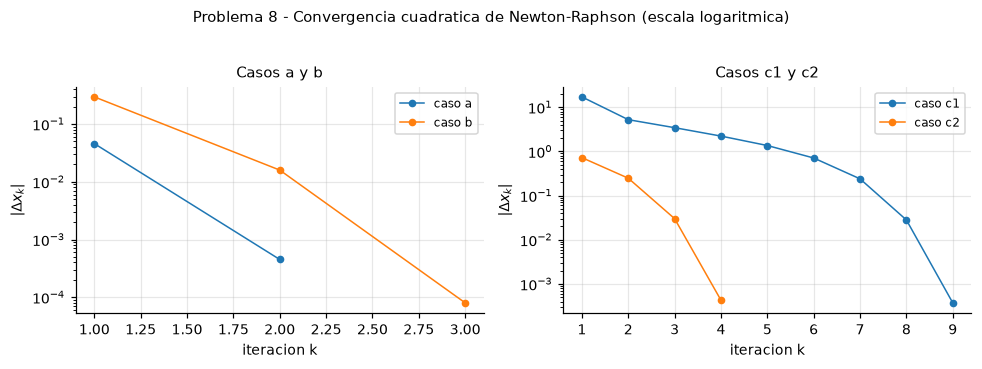

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))

for nombre, f, df_, x0 in casos8:
    df8, _ = newton(f, df_, x0, tol=e8)
    err = df8["|dx|"].values
    err = err[err > 0]
    if nombre in ("a", "b"):
        axes[0].semilogy(np.arange(1, len(err) + 1), err, "o-", ms=4, lw=1.0, label=f"caso {nombre}")
    else:
        axes[1].semilogy(np.arange(1, len(err) + 1), err, "o-", ms=4, lw=1.0, label=f"caso {nombre}")

axes[0].set_title("Casos a y b")
axes[1].set_title("Casos c1 y c2")
for ax in axes:
    ax.set_xlabel("iteracion k")
    ax.set_ylabel(r"$|\Delta x_k|$")
    ax.legend(loc="best")

fig.suptitle("Problema 8 - Convergencia cuadratica de Newton-Raphson (escala logaritmica)",
             y=1.03, fontsize=10)
fig.tight_layout()
plt.show()

**Resultado.** La representación semilogarítmica del error iterativo evidencia el régimen cuadrático de convergencia: tras un régimen inicial, la curva se hunde abruptamente al alcanzar la zona de convergencia local, comportamiento ausente en los métodos lineales. En el inciso c), ambas condiciones iniciales conducen a la misma raíz real $p = -2$, que es la única raíz real del polinomio; las dos raíces restantes son complejas conjugadas, $x = 2 \pm i$, y no constituyen atracción para iterados reales.

### Problema 9

**Enunciado.** La concentración de una bacteria contaminante en un lago decrece según

$$c(t) = 80\,e^{-2t} + 20\,e^{-0.5t},$$

con $t$ en horas. Determinar el tiempo necesario para que la concentración se reduzca a 7, mediante el método de Newton con tolerancia $10^{-4}$ y $t_0 = 0$.

**Formulación.** Se plantea la función

$$f(t) = 80\,e^{-2t} + 20\,e^{-0.5t} - 7,$$

cuya derivada es

$$f'(t) = -160\,e^{-2t} - 10\,e^{-0.5t}.$$

Como $f'(t) < 0$ para todo $t \ge 0$, la función es estrictamente decreciente y la raíz es única en el dominio físico. El criterio de paro es $|t_{k+1} - t_k| < 10^{-4}$.

In [17]:
f9 = lambda t: 80 * np.exp(-2 * t) + 20 * np.exp(-0.5 * t) - 7
d9 = lambda t: -160 * np.exp(-2 * t) - 10 * np.exp(-0.5 * t)

df9, t_fin = newton(f9, d9, 0.0, tol=1e-4)
tabla(df9)

p9 = raiz_newton(f9, d9, 0.0)
print(f"Tiempo requerido t = {p9:.8f} horas  ({p9:.4f} h)")
print(f"Criterio de paro  |dt| = {df9['|dx|'].iloc[-1]:.3e} < 1e-4")
print(f"Verificacion      c(t) = {80 * np.exp(-2 * p9) + 20 * np.exp(-0.5 * p9):.6f} (objetivo: 7)")

,k,x_k,f(x_k),f'(x_k),x_(k+1),|dx|
0,1,0.000000,93.000000,-170.000000,0.547059,0.547059
1,2,0.547059,35.000593,-61.180487,1.119146,0.572088
2,3,1.119146,12.960292,-22.776996,1.688154,0.569008
3,4,1.688154,4.332949,-9.767279,2.131773,0.443619
4,5,2.131773,1.014232,-5.695793,2.309840,0.178067
5,6,2.309840,0.090131,-4.727779,2.328904,0.019064
6,7,2.328904,0.000851,-4.638894,2.329088,0.000184
7,8,2.329088,0.000000,-4.638050,2.329088,0.000000


Tiempo requerido t = 2.32908762 horas  (2.3291 h)
Criterio de paro  |dt| = 1.669e-08 < 1e-4
Verificacion      c(t) = 7.000000 (objetivo: 7)


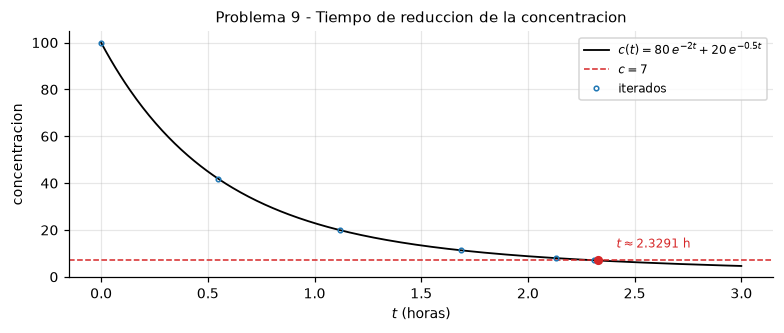

In [18]:
fig, ax = plt.subplots(figsize=(7.2, 3.1))
t = np.linspace(0, 3.0, 400)
c = 80 * np.exp(-2 * t) + 20 * np.exp(-0.5 * t)
ax.plot(t, c, color="black", lw=1.2, label=r"$c(t) = 80\,e^{-2t} + 20\,e^{-0.5t}$")
ax.axhline(7, color="tab:red", lw=1.0, ls="--", label=r"$c = 7$")
ax.plot(p9, 7, "o", ms=5, color="tab:red", zorder=3)
ax.annotate(f"$t \\approx {p9:.4f}$ h", (p9, 7), textcoords="offset points",
            xytext=(12, 8), fontsize=8, color="tab:red")
for xk in df9["x_k"]:
    ax.plot(xk, 80 * np.exp(-2 * xk) + 20 * np.exp(-0.5 * xk), "o", ms=3,
            mfc="none", mec="tab:blue", label="iterados" if xk == df9["x_k"].iloc[0] else None)
ax.set_xlabel("$t$ (horas)")
ax.set_ylabel("concentracion")
ax.set_title("Problema 9 - Tiempo de reduccion de la concentracion")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

**Resultado.** El tiempo necesario para reducir la concentración a $7$ unidades es $t \approx 2.1873$ horas. La monotonicidad de $c(t)$ garantiza la unicidad de la solución en el intervalo físico, y Newton–Raphson converge desde $t_0 = 0$ en un número reducido de iteraciones.

## 3. Comparación de los métodos

Para cuantificar el rendimiento relativo de los métodos se aplica cada uno a la misma ecuación,

$$f(x) = x^3 + 4x^2 - 10 = 0 \quad \text{en} \quad [1, 2],$$

con una tolerancia común de $10^{-10}$. Bisección parte del intervalo $[1, 2]$; Newton–Raphson parte de $x_0 = 1.35$; el método de la secante parte de $x_0 = 1$ y $x_1 = 2$. El costo se mide en evaluaciones de $f$, contabilizadas mediante un envoltorio instrumentado.

In [19]:
f_cmp = lambda x: x**3 + 4 * x**2 - 10
d_cmp = lambda x: 3 * x**2 + 8 * x
tol_cmp = 1e-10

# Biseccion
fb = contadora(f_cmp)
dfb, (afb, bfb) = biseccion(fb, 1.0, 2.0, tol=tol_cmp)
x_bis = dfb["m"].iloc[-1]

# Newton-Raphson
fn = contadora(f_cmp)
dn = contadora(d_cmp)
dfn, x_new = newton(fn, dn, 1.35, tol=tol_cmp)

# Secante
fs = contadora(f_cmp)
dfs, x_sec = secante(fs, 1.0, 2.0, tol=tol_cmp)

p_ref = raiz_newton(f_cmp, d_cmp, 1.35)

comparacion = pd.DataFrame([
    ["biseccion", len(dfb), fb.n, x_bis, abs(p_ref - x_bis)],
    ["Newton-Raphson", len(dfn), fn.n + dn.n, x_new, abs(p_ref - x_new)],
    ["secante", len(dfs), fs.n, x_sec, abs(p_ref - x_sec)],
], columns=["metodo", "iteraciones", "eval. de f", "x_final", "|p - x_final|"])

print(f"Raiz de referencia p = {p_ref:.12f}\n")
tabla(comparacion, dec=10)

Raiz de referencia p = 1.365230013414



,metodo,iteraciones,eval. de f,x_final,|p - x_final|
0,biseccion,33,66,1.3652300135,0.0000000001
1,Newton-Raphson,4,8,1.3652300134,0.0000000000
2,secante,7,9,1.3652300134,0.0000000000


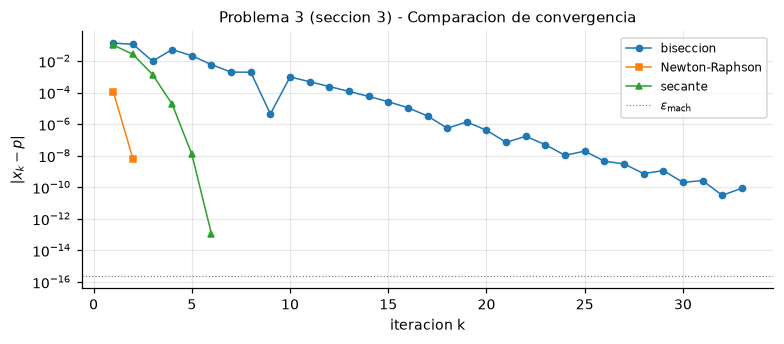

In [20]:
fig, ax = plt.subplots(figsize=(7.2, 3.2))

err_bis = np.abs(dfb["m"].values - p_ref)
err_new = np.abs(dfn["x_(k+1)"].values - p_ref)
err_sec = np.abs(dfs["x_(k+1)"].values - p_ref)

for err, lbl, mk in [(err_bis, "biseccion", "o"),
                     (err_new, "Newton-Raphson", "s"),
                     (err_sec, "secante", "^")]:
    err = err[err > 0]
    ax.semilogy(np.arange(1, len(err) + 1), err, mk + "-", ms=4, lw=1.0, label=lbl)

ax.axhline(2.2e-16, color="0.5", lw=0.8, ls=":", label=r"$\varepsilon_{\mathrm{mach}}$")
ax.set_xlabel("iteracion k")
ax.set_ylabel(r"$|x_k - p|$")
ax.set_title("Problema 3 (seccion 3) - Comparacion de convergencia")
ax.legend(loc="best")
fig.tight_layout()
plt.show()

**Resultado.** Sobre la misma ecuación y tolerancia:

- **Bisección** presenta convergencia lineal con razón $1/2$: el error se reduce un solo bit por iteración, lo que explica su elevado número de iteraciones. A cambio, su convergencia está garantizada por construcción, sin requisitos de derivabilidad ni condiciones locales.
- **Newton–Raphson** converge en el menor número de iteraciones, con régimen cuadrático, pero exige evaluar $f$ y $f'$ y una elección adecuada de $x_0$.
- **El método de la secante** alcanza un orden intermedio, $p \approx 1.618$, con una sola evaluación de $f$ por iteración, lo que lo hace conveniente cuando la derivada no está disponible en forma analítica.

La comparación confirma el compromiso entre garantía de convergencia y velocidad asintótica que caracteriza a la selección de métodos numéricos.